In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.random.seed(42)

print("シミュレーション環境の準備完了")

シミュレーション環境の準備完了


In [9]:
# URDFを参考にしたロボットパラメータ
WHEEL_RADIUS = 0.05       # 車輪半径 [m]
WHEEL_BASE = 0.20         # 左右車輪間隔 [m]
BODY_LENGTH = 0.24        # 車体長さ [m]
BODY_WIDTH = 0.18         # 車体幅 [m]
BODY_MASS = 1.0           # 車体質量 [kg]

# シミュレーション条件
DT = 0.02                 # 時間刻み [s]
SIM_TIME = 20.0           # シミュレーション時間 [s]
STEPS = int(SIM_TIME / DT)

MAX_WHEEL_SPEED = 8.0     # 車輪角速度上限 [rad/s]
WHEEL_TAU = 0.15          # 車輪応答時定数 [s]
LOOKAHEAD = 0.25          # Pure Pursuitの注視距離 [m]
TARGET_SPEED = 0.18       # 目標並進速度 [m/s]

# 目標経路：正弦波状の曲線
path_x = np.linspace(0, 3.0, 601)
path_y = 0.45 * np.sin(1.5 * path_x)
path = np.column_stack((path_x, path_y))

# 経路上の距離
path_ds = np.linalg.norm(np.diff(path, axis=0), axis=1)
path_s = np.concatenate(([0.0], np.cumsum(path_ds)))

print(f"車輪半径: {WHEEL_RADIUS} m")
print(f"左右車輪間隔: {WHEEL_BASE} m")
print(f"目標経路長: {path_s[-1]:.2f} m")

車輪半径: 0.05 m
左右車輪間隔: 0.2 m
目標経路長: 3.33 m


In [10]:
def wrap_angle(angle):
    """角度を -pi ～ pi に変換"""
    return (angle + np.pi) % (2 * np.pi) - np.pi


def pure_pursuit(x, y, theta, path, path_s,
                 lookahead=LOOKAHEAD):
    """Pure Pursuitによる経路追従制御"""

    # 現在位置に最も近い経路点
    distances = np.linalg.norm(
        path - np.array([x, y]), axis=1
    )
    nearest_idx = np.argmin(distances)

    # 注視距離だけ先の経路点を選択
    target_s = path_s[nearest_idx] + lookahead
    target_idx = np.searchsorted(path_s, target_s)
    target_idx = min(target_idx, len(path) - 1)

    target = path[target_idx]

    # 目標点をロボット座標系で評価
    alpha = wrap_angle(
        np.arctan2(target[1] - y, target[0] - x) - theta
    )

    # 曲率と角速度
    actual_lookahead = max(
        np.linalg.norm(target - np.array([x, y])), 1e-6
    )
    curvature = 2.0 * np.sin(alpha) / actual_lookahead

    # 終点付近では速度を落とす
    remaining = np.linalg.norm(
        path[-1] - np.array([x, y])
    )
    v = min(TARGET_SPEED, 0.8 * remaining)

    omega = v * curvature

    return v, omega, target_idx


def simulate():
    """ロボットの走行シミュレーション"""

    # 状態 [x, y, theta]
    x, y, theta = 0.0, -0.15, 0.0

    # 左右車輪の実際の角速度
    wl = 0.0
    wr = 0.0

    history = {
        "time": [],
        "x": [],
        "y": [],
        "theta": [],
        "wl": [],
        "wr": [],
        "v": [],
        "omega": [],
        "error": [],
        "target_idx": [],
    }

    for k in range(STEPS):
        t = k * DT

        # 経路追従コントローラ
        v_cmd, omega_cmd, target_idx = pure_pursuit(
            x, y, theta, path, path_s
        )

        # 並進・旋回速度から左右車輪の指令を計算
        wl_cmd = (
            v_cmd - omega_cmd * WHEEL_BASE / 2
        ) / WHEEL_RADIUS

        wr_cmd = (
            v_cmd + omega_cmd * WHEEL_BASE / 2
        ) / WHEEL_RADIUS

        # 車輪速度の上限制約
        wl_cmd = np.clip(
            wl_cmd, -MAX_WHEEL_SPEED, MAX_WHEEL_SPEED
        )
        wr_cmd = np.clip(
            wr_cmd, -MAX_WHEEL_SPEED, MAX_WHEEL_SPEED
        )

        # 車輪の一次遅れモデル
        wl += (wl_cmd - wl) * DT / WHEEL_TAU
        wr += (wr_cmd - wr) * DT / WHEEL_TAU

        # 実際の車体速度
        v = WHEEL_RADIUS * (wr + wl) / 2
        omega = WHEEL_RADIUS * (wr - wl) / WHEEL_BASE

        # オドメトリの誤差を模擬する微小な外乱
        v_actual = v + np.random.normal(0, 0.002)
        omega_actual = omega + np.random.normal(0, 0.005)

        # ロボットの運動学
        x += v_actual * np.cos(theta) * DT
        y += v_actual * np.sin(theta) * DT
        theta = wrap_angle(theta + omega_actual * DT)

        # 経路追従誤差
        error = np.min(
            np.linalg.norm(path - np.array([x, y]), axis=1)
        )

        for key, value in [
            ("time", t),
            ("x", x),
            ("y", y),
            ("theta", theta),
            ("wl", wl),
            ("wr", wr),
            ("v", v),
            ("omega", omega),
            ("error", error),
            ("target_idx", target_idx),
        ]:
            history[key].append(value)

        # 経路終端に到達したら終了
        if np.linalg.norm(path[-1] - np.array([x, y])) < 0.03:
            break

    return {
        key: np.asarray(value)
        for key, value in history.items()
    }


result = simulate()

print(f"シミュレーション時間: {result['time'][-1]:.2f} s")
print(f"最終位置: ({result['x'][-1]:.3f}, "
      f"{result['y'][-1]:.3f}) m")

シミュレーション時間: 19.98 s
最終位置: (2.964, -0.433) m


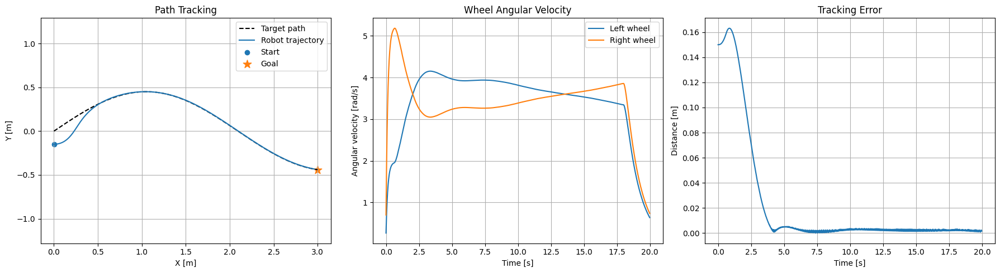

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 走行軌跡
ax = axes[0]
ax.plot(path[:, 0], path[:, 1],
        "k--", label="Target path")
ax.plot(result["x"], result["y"],
        label="Robot trajectory")
ax.scatter(
    result["x"][0], result["y"][0],
    marker="o", label="Start"
)
ax.scatter(
    path[-1, 0], path[-1, 1],
    marker="*", s=120, label="Goal"
)
ax.set_title("Path Tracking")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.axis("equal")
ax.grid(True)
ax.legend()

# 2. 左右車輪速度
ax = axes[1]
ax.plot(result["time"], result["wl"],
        label="Left wheel")
ax.plot(result["time"], result["wr"],
        label="Right wheel")
ax.set_title("Wheel Angular Velocity")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Angular velocity [rad/s]")
ax.grid(True)
ax.legend()

# 3. 追従誤差
ax = axes[2]
ax.plot(result["time"], result["error"])
ax.set_title("Tracking Error")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Distance [m]")
ax.grid(True)

plt.tight_layout()
plt.show()

In [12]:
errors = result["error"]

rmse = np.sqrt(np.mean(errors ** 2))
mean_error = np.mean(errors)
max_error = np.max(errors)
final_error = np.linalg.norm(
    np.array([result["x"][-1], result["y"][-1]])
    - path[-1]
)

print("===== 経路追従性能 =====")
print(f"平均追従誤差 : {mean_error:.4f} m")
print(f"RMSE         : {rmse:.4f} m")
print(f"最大追従誤差 : {max_error:.4f} m")
print(f"終点位置誤差 : {final_error:.4f} m")
print(f"走行時間     : {result['time'][-1]:.2f} s")

===== 経路追従性能 =====
平均追従誤差 : 0.0213 m
RMSE         : 0.0502 m
最大追従誤差 : 0.1631 m
終点位置誤差 : 0.0369 m
走行時間     : 19.98 s


In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(path[:, 0], path[:, 1], "k--",
        alpha=0.6, label="Target path")
trajectory, = ax.plot([], [], label="Robot trajectory")
robot_body = plt.Rectangle(
    (0, 0), BODY_LENGTH, BODY_WIDTH,
    fill=False, linewidth=2
)
ax.add_patch(robot_body)

ax.set_xlim(-0.3, 3.4)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_title("Differential Drive Robot")
ax.grid(True)
ax.legend()

# 表示フレームを間引いて軽量化
frame_indices = np.arange(0, len(result["x"]), 10)
if frame_indices[-1] != len(result["x"]) - 1:
    frame_indices = np.append(
        frame_indices, len(result["x"]) - 1
    )


def update(frame):
    i = frame_indices[frame]

    trajectory.set_data(
        result["x"][:i + 1],
        result["y"][:i + 1]
    )

    # 車体中心を基準に矩形を回転・配置
    theta = result["theta"][i]
    center = np.array([result["x"][i], result["y"][i]])

    corners = np.array([
        [-BODY_LENGTH / 2, -BODY_WIDTH / 2],
        [ BODY_LENGTH / 2, -BODY_WIDTH / 2],
        [ BODY_LENGTH / 2,  BODY_WIDTH / 2],
        [-BODY_LENGTH / 2,  BODY_WIDTH / 2],
    ])

    rotation = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    rotated = corners @ rotation.T + center

    from matplotlib.patches import Polygon

    if not hasattr(update, "body_patch"):
        update.body_patch = Polygon(
            rotated, closed=True, fill=False,
            edgecolor="tab:red", linewidth=2
        )
        ax.add_patch(update.body_patch)
    else:
        update.body_patch.set_xy(rotated)

    return trajectory, update.body_patch


ani = FuncAnimation(
    fig, update, frames=len(frame_indices),
    interval=30, blit=False
)

plt.close(fig)
display(HTML(ani.to_jshtml()))

In [14]:

# 3Dアニメーション（既存の result, path などを再利用）
!pip -q install plotly

import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# 表示フレームを間引く
stride = max(1, len(result["x"]) // 150)
frame_indices = list(range(0, len(result["x"]), stride))
if frame_indices[-1] != len(result["x"]) - 1:
    frame_indices.append(len(result["x"]) - 1)

# 3Dモデルの寸法
L = BODY_LENGTH
B = BODY_WIDTH
R = WHEEL_RADIUS
Z_BODY = 0.07          # 車体底面の高さ [m]
WHEEL_THICKNESS = 0.025

# 車体の8頂点（ローカル座標）
body_local = np.array([
    [-L/2, -B/2, Z_BODY],
    [ L/2, -B/2, Z_BODY],
    [ L/2,  B/2, Z_BODY],
    [-L/2,  B/2, Z_BODY],
    [-L/2, -B/2, Z_BODY + 0.08],
    [ L/2, -B/2, Z_BODY + 0.08],
    [ L/2,  B/2, Z_BODY + 0.08],
    [-L/2,  B/2, Z_BODY + 0.08],
])

# 直方体の辺
edges = [
    (0,1),(1,2),(2,3),(3,0),
    (4,5),(5,6),(6,7),(7,4),
    (0,4),(1,5),(2,6),(3,7)
]

def transform_points(points, x, y, theta):
    """ローカル座標をワールド座標に変換"""
    c, s = np.cos(theta), np.sin(theta)
    rot = np.array([
        [c, -s, 0],
        [s,  c, 0],
        [0,  0, 1]
    ])
    return points @ rot.T + np.array([x, y, 0])

def make_body(x, y, theta):
    p = transform_points(body_local, x, y, theta)
    xs, ys, zs = [], [], []
    for a, b in edges:
        xs += [p[a, 0], p[b, 0], None]
        ys += [p[a, 1], p[b, 1], None]
        zs += [p[a, 2], p[b, 2], None]
    return go.Scatter3d(
        x=xs, y=ys, z=zs,
        mode="lines",
        line=dict(color="crimson", width=7),
        name="Robot body"
    )

def make_wheel(x, y, theta, side):
    """左右車輪を円形リングとして表示"""
    phi = np.linspace(0, 2*np.pi, 40)
    wheel_y = side * WHEEL_BASE / 2

    # 車輪の回転軸はロボット座標系のY方向
    local = np.column_stack([
        R * np.cos(phi),
        np.full_like(phi, wheel_y),
        R * np.sin(phi) + R
    ])
    p = transform_points(local, x, y, theta)

    return go.Scatter3d(
        x=p[:, 0], y=p[:, 1], z=p[:, 2],
        mode="lines",
        line=dict(color="royalblue", width=6),
        name="Left wheel" if side > 0 else "Right wheel"
    )

def make_axle(x, y, theta):
    p = transform_points(np.array([
        [0, -WHEEL_BASE/2, R],
        [0,  WHEEL_BASE/2, R]
    ]), x, y, theta)
    return go.Scatter3d(
        x=p[:, 0], y=p[:, 1], z=p[:, 2],
        mode="lines",
        line=dict(color="gray", width=5),
        name="Axle"
    )

def make_heading(x, y, theta):
    # ロボットの前方を示す線
    p = transform_points(np.array([
        [0, 0, Z_BODY + 0.10],
        [0.13, 0, Z_BODY + 0.10]
    ]), x, y, theta)
    return go.Scatter3d(
        x=p[:, 0], y=p[:, 1], z=p[:, 2],
        mode="lines",
        line=dict(color="green", width=7),
        name="Heading"
    )

def dynamic_traces(i):
    x = result["x"][i]
    y = result["y"][i]
    theta = result["theta"][i]

    # 走行済み軌跡
    trajectory = go.Scatter3d(
        x=result["x"][:i+1],
        y=result["y"][:i+1],
        z=np.full(i+1, 0.01),
        mode="lines",
        line=dict(color="orange", width=5),
        name="Trajectory"
    )

    return [
        trajectory,
        make_body(x, y, theta),
        make_wheel(x, y, theta, -1),
        make_wheel(x, y, theta, 1),
        make_axle(x, y, theta),
        make_heading(x, y, theta)
    ]

# 目標経路
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=path[:, 0],
    y=path[:, 1],
    z=np.full(len(path), 0.01),
    mode="lines",
    line=dict(color="black", width=4, dash="dash"),
    name="Target path"
))

# 初期状態
fig.add_traces(dynamic_traces(frame_indices[0]))

# アニメーションフレーム
frames = []
for frame_no, i in enumerate(frame_indices):
    frames.append(go.Frame(
        name=str(frame_no),
        data=dynamic_traces(i),
        traces=[1, 2, 3, 4, 5, 6]
    ))

fig.frames = frames

# 再生・一時停止ボタンとスライダー
fig.update_layout(
    title="3D Differential Drive Robot Simulation",
    scene=dict(
        xaxis_title="X [m]",
        yaxis_title="Y [m]",
        zaxis_title="Z [m]",
        xaxis=dict(range=[-0.3, 3.4]),
        yaxis=dict(range=[-1.2, 1.2]),
        zaxis=dict(range=[0, 0.5]),
        aspectmode="manual",
        aspectratio=dict(x=2.5, y=1.5, z=0.6),
        camera=dict(eye=dict(x=1.5, y=-2.0, z=1.5))
    ),
    updatemenus=[dict(
        type="buttons",
        showactive=False,
        x=0.05,
        y=1.12,
        buttons=[
            dict(
                label="▶ 再生",
                method="animate",
                args=[None, {
                    "frame": {"duration": 40, "redraw": True},
                    "transition": {"duration": 0},
                    "fromcurrent": True
                }]
            ),
            dict(
                label="⏸ 停止",
                method="animate",
                args=[[None], {
                    "frame": {"duration": 0, "redraw": False},
                    "mode": "immediate",
                    "transition": {"duration": 0}
                }]
            )
        ]
    )],
    sliders=[dict(
        active=0,
        currentvalue=dict(prefix="Frame: "),
        steps=[
            dict(
                method="animate",
                args=[[str(j)], {
                    "frame": {"duration": 0, "redraw": True},
                    "mode": "immediate",
                    "transition": {"duration": 0}
                }],
                label=str(j)
            )
            for j in range(len(frame_indices))
        ]
    )],
    height=700
)

fig.show()
